# NB\_C03: Structural MRI -- Anatomy, Segmentation, and Lesions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C03_Structural_MRI_Segmentation.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 6 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.13 and Opus 4.6

---

## Objectives

- Visualise T1-weighted MRI images in orthogonal planes (pre-op and post-op)
- Understand tumour segmentation and resection cavity identification
- Explore FreeSurfer cortical parcellation (aparc+aseg) and tissue classification
- Appreciate how structural anatomy informs the FE mesh (NB\_C06) and connectivity (NB\_C04, NB\_C05)

**Prerequisites:** [NB\_C01](NB_C01_Digital_Twin_Concept_and_Data.ipynb)  
**Next:** [NB\_C04](NB_C04_Diffusion_MRI_Tractography.ipynb) (diffusion MRI)

---
## 1. T1-Weighted MRI: What It Shows

T1-weighted (T1w) MRI exploits differences in the longitudinal relaxation
time ($T_1$) of hydrogen nuclei in different tissues to produce
**anatomical contrast**:

| Tissue | $T_1$ at 3T | Appearance on T1w |
|--------|-------------|-------------------|
| White matter | ~830 ms | Bright (short $T_1$, rapid recovery) |
| Gray matter | ~1300 ms | Intermediate |
| CSF | ~4000 ms | Dark (long $T_1$, slow recovery) |
| Tumour | Variable | Often isointense to gray matter; may enhance with contrast |
| Post-op cavity | ~4000 ms | Dark (CSF-filled) |

For the digital twin, T1w images serve three critical purposes:

1. **Domain definition**: the brain surface defines the computational
   domain $\Omega$ for FEM simulation
2. **Tissue classification**: segmentation into white matter, gray matter,
   CSF, and tumour defines material properties
3. **Parcellation**: cortical parcellation (Desikan-Killiany atlas) defines
   the 68 ROIs used for connectivity analysis

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import nibabel as nib
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python {REPO_ROOT}/data/download_data.py --capstone
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

BIDS_ROOT   = REPO_ROOT / 'data' / 'BIDS_preop_postop'
DERIV_PROJ  = REPO_ROOT / 'derivatives'
REG_DIR     = DERIV_PROJ / 'registered_t1w' / 'sub-PAT16'
FMRIPREP    = DERIV_PROJ / 'fmriprep' / 'sub-PAT16'
FIG_DIR     = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

def _to_ras(img):
    """Reorient a NIfTI image to RAS+ canonical axes."""
    return nib.as_closest_canonical(img)

print(f'BIDS root: {BIDS_ROOT}')
print(f'Registration dir: {REG_DIR}')

BIDS root: <REPO_ROOT>/data/BIDS_preop_postop
Registration dir: <REPO_ROOT>/derivatives/registered_t1w/sub-PAT16


---
## 2. Pre-operative T1w

The pre-operative scan shows the intact brain with the tumour in situ.
We display three orthogonal planes (axial, sagittal, coronal) to
appreciate the tumour's location and extent.

Pre-op T1w: shape=(160, 256, 256), orientation=('R', 'A', 'S'), voxel size=(1.0000021, 1.0, 1.0)


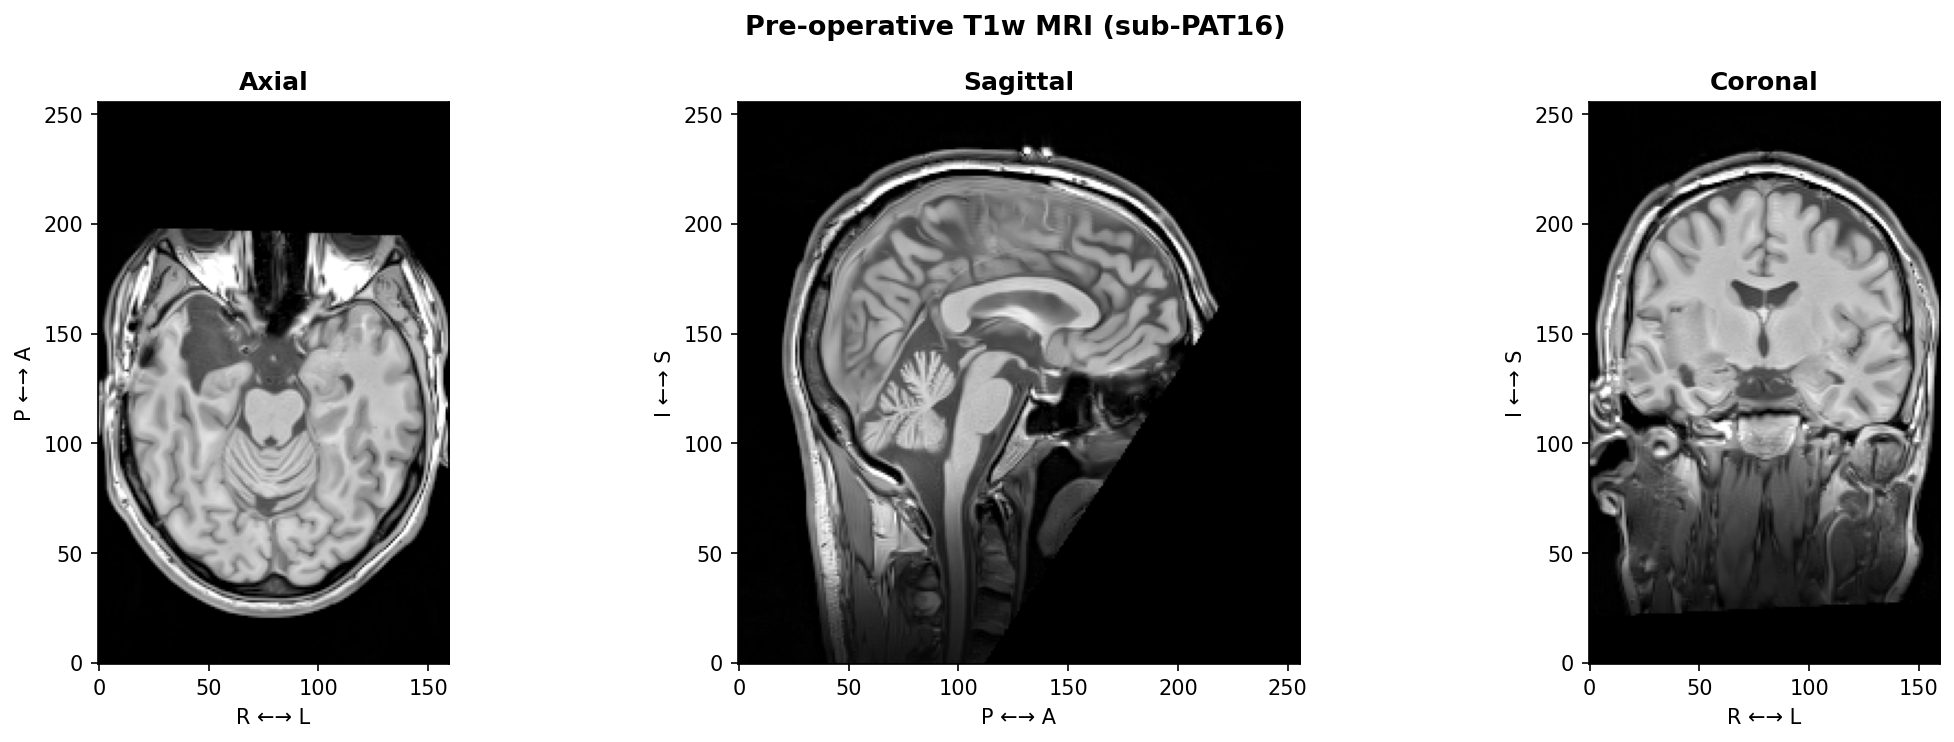

In [2]:
# Load pre-op T1w
t1_preop_path = BIDS_ROOT / 'sub-PAT16' / 'ses-preop' / 'anat' / 'sub-PAT16_ses-preop_T1w.nii.gz'
t1_preop_fmriprep = FMRIPREP / 'ses-preop' / 'anat' / 'sub-PAT16_ses-preop_desc-preproc_T1w.nii.gz'

t1_path = t1_preop_fmriprep if t1_preop_fmriprep.exists() else t1_preop_path
t1_preop_img  = _to_ras(nib.load(str(t1_path)))
t1_preop_data = np.asarray(t1_preop_img.dataobj).astype(np.float32)
print(f'Pre-op T1w: shape={t1_preop_data.shape}, '
      f'orientation={nib.aff2axcodes(t1_preop_img.affine)}, '
      f'voxel size={t1_preop_img.header.get_zooms()[:3]}')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Pre-operative T1w MRI (sub-PAT16)', fontsize=13, fontweight='bold')

s = t1_preop_data.shape
vmax = np.percentile(t1_preop_data[t1_preop_data > 0], 99)

# Radiological convention (RAS): patient R on viewer's left
axes[0].imshow(t1_preop_data[::-1, :, s[2]//2].T, origin='lower',
               cmap='gray', vmax=vmax, aspect='equal')
axes[0].set_title('Axial', fontweight='bold')
axes[0].set_xlabel('R \u2190\u2192 L'); axes[0].set_ylabel('P \u2190\u2192 A')

axes[1].imshow(t1_preop_data[s[0]//2, :, :].T, origin='lower',
               cmap='gray', vmax=vmax, aspect='equal')
axes[1].set_title('Sagittal', fontweight='bold')
axes[1].set_xlabel('P \u2190\u2192 A'); axes[1].set_ylabel('I \u2190\u2192 S')

axes[2].imshow(t1_preop_data[::-1, s[1]//2, :].T, origin='lower',
               cmap='gray', vmax=vmax, aspect='equal')
axes[2].set_title('Coronal', fontweight='bold')
axes[2].set_xlabel('R \u2190\u2192 L'); axes[2].set_ylabel('I \u2190\u2192 S')

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC03_01_t1w_preop.png', bbox_inches='tight')
plt.show()

---
## 3. Post-operative T1w

The post-operative scan (~6 months after surgery) shows the resection
cavity -- a CSF-filled space where the tumour was removed.

Post-op T1w: shape=(160, 256, 256), orientation=('R', 'A', 'S'), voxel size=(1.0000061, 1.0, 1.0)


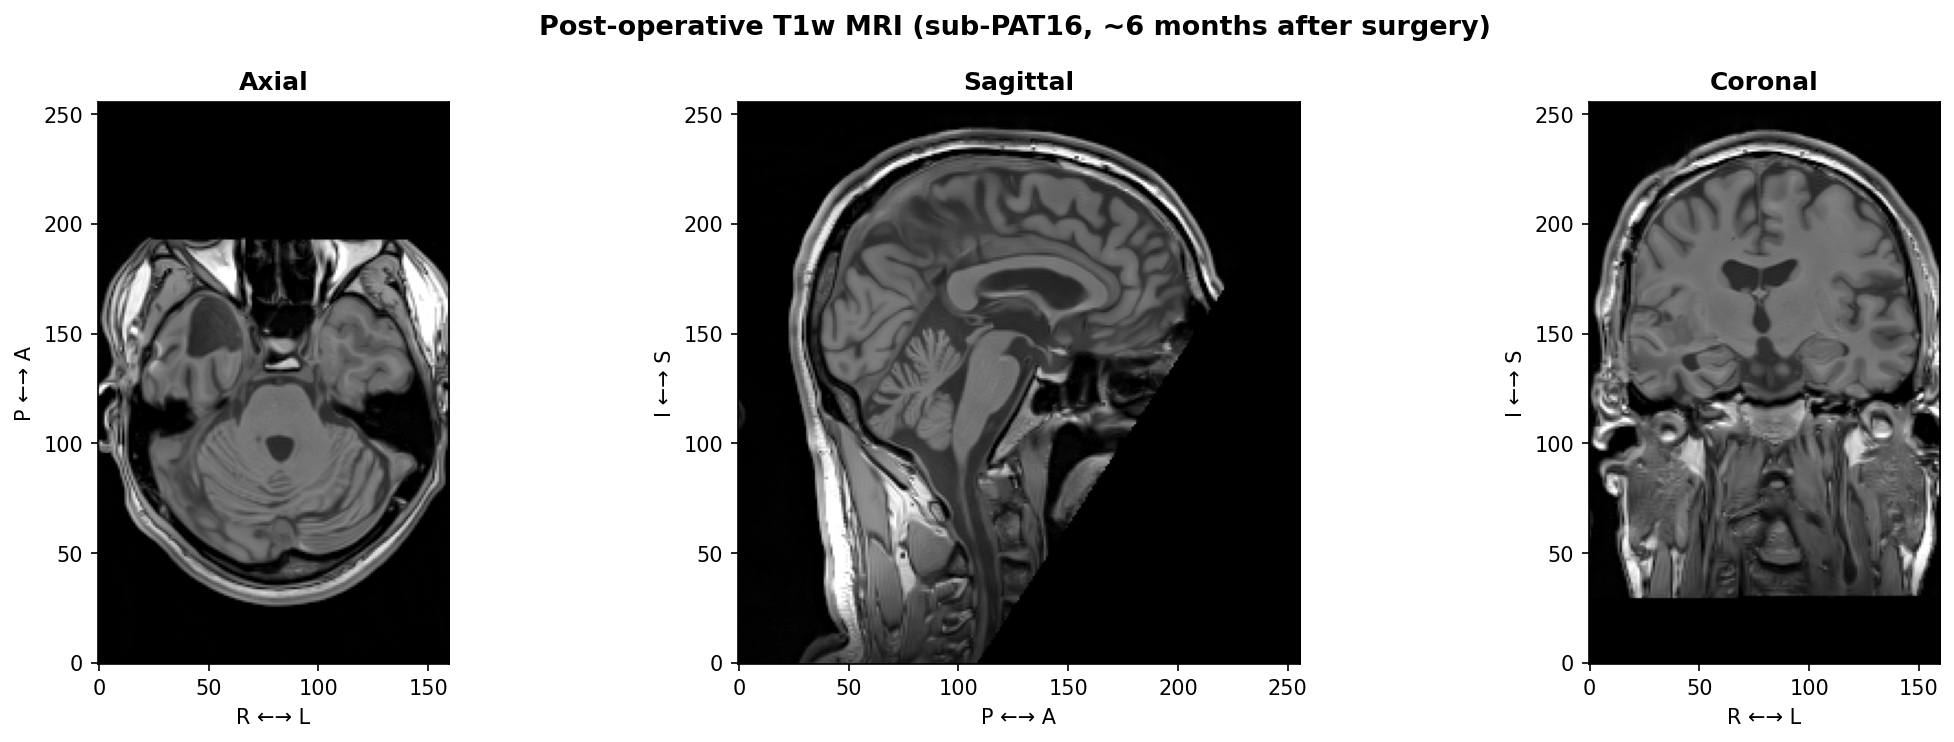

In [3]:
t1_postop_path = BIDS_ROOT / 'sub-PAT16' / 'ses-postop' / 'anat' / 'sub-PAT16_ses-postop_T1w.nii.gz'
t1_postop_fmriprep = FMRIPREP / 'ses-postop' / 'anat' / 'sub-PAT16_ses-postop_desc-preproc_T1w.nii.gz'

t1_post_path = t1_postop_fmriprep if t1_postop_fmriprep.exists() else t1_postop_path
t1_postop_img  = _to_ras(nib.load(str(t1_post_path)))
t1_postop_data = np.asarray(t1_postop_img.dataobj).astype(np.float32)
print(f'Post-op T1w: shape={t1_postop_data.shape}, '
      f'orientation={nib.aff2axcodes(t1_postop_img.affine)}, '
      f'voxel size={t1_postop_img.header.get_zooms()[:3]}')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Post-operative T1w MRI (sub-PAT16, ~6 months after surgery)',
             fontsize=13, fontweight='bold')

s2 = t1_postop_data.shape
vmax2 = np.percentile(t1_postop_data[t1_postop_data > 0], 99)

# Radiological convention (RAS): patient R on viewer's left
axes[0].imshow(t1_postop_data[::-1, :, s2[2]//2].T, origin='lower',
               cmap='gray', vmax=vmax2, aspect='equal')
axes[0].set_title('Axial', fontweight='bold')
axes[0].set_xlabel('R \u2190\u2192 L'); axes[0].set_ylabel('P \u2190\u2192 A')

axes[1].imshow(t1_postop_data[s2[0]//2, :, :].T, origin='lower',
               cmap='gray', vmax=vmax2, aspect='equal')
axes[1].set_title('Sagittal', fontweight='bold')
axes[1].set_xlabel('P \u2190\u2192 A'); axes[1].set_ylabel('I \u2190\u2192 S')

axes[2].imshow(t1_postop_data[::-1, s2[1]//2, :].T, origin='lower',
               cmap='gray', vmax=vmax2, aspect='equal')
axes[2].set_title('Coronal', fontweight='bold')
axes[2].set_xlabel('R \u2190\u2192 L'); axes[2].set_ylabel('I \u2190\u2192 S')

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC03_02_t1w_postop.png', bbox_inches='tight')
plt.show()

---
## 4. Tumour and Resection Cavity Segmentation

The pre-operative tumour mask and post-operative cavity mask delineate
the pathological regions. The tumour mask was created from the original
BTC dataset; the cavity can be identified from the post-op segmentation.

Tumour mask loaded: 45431 voxels = 45.4 cm³


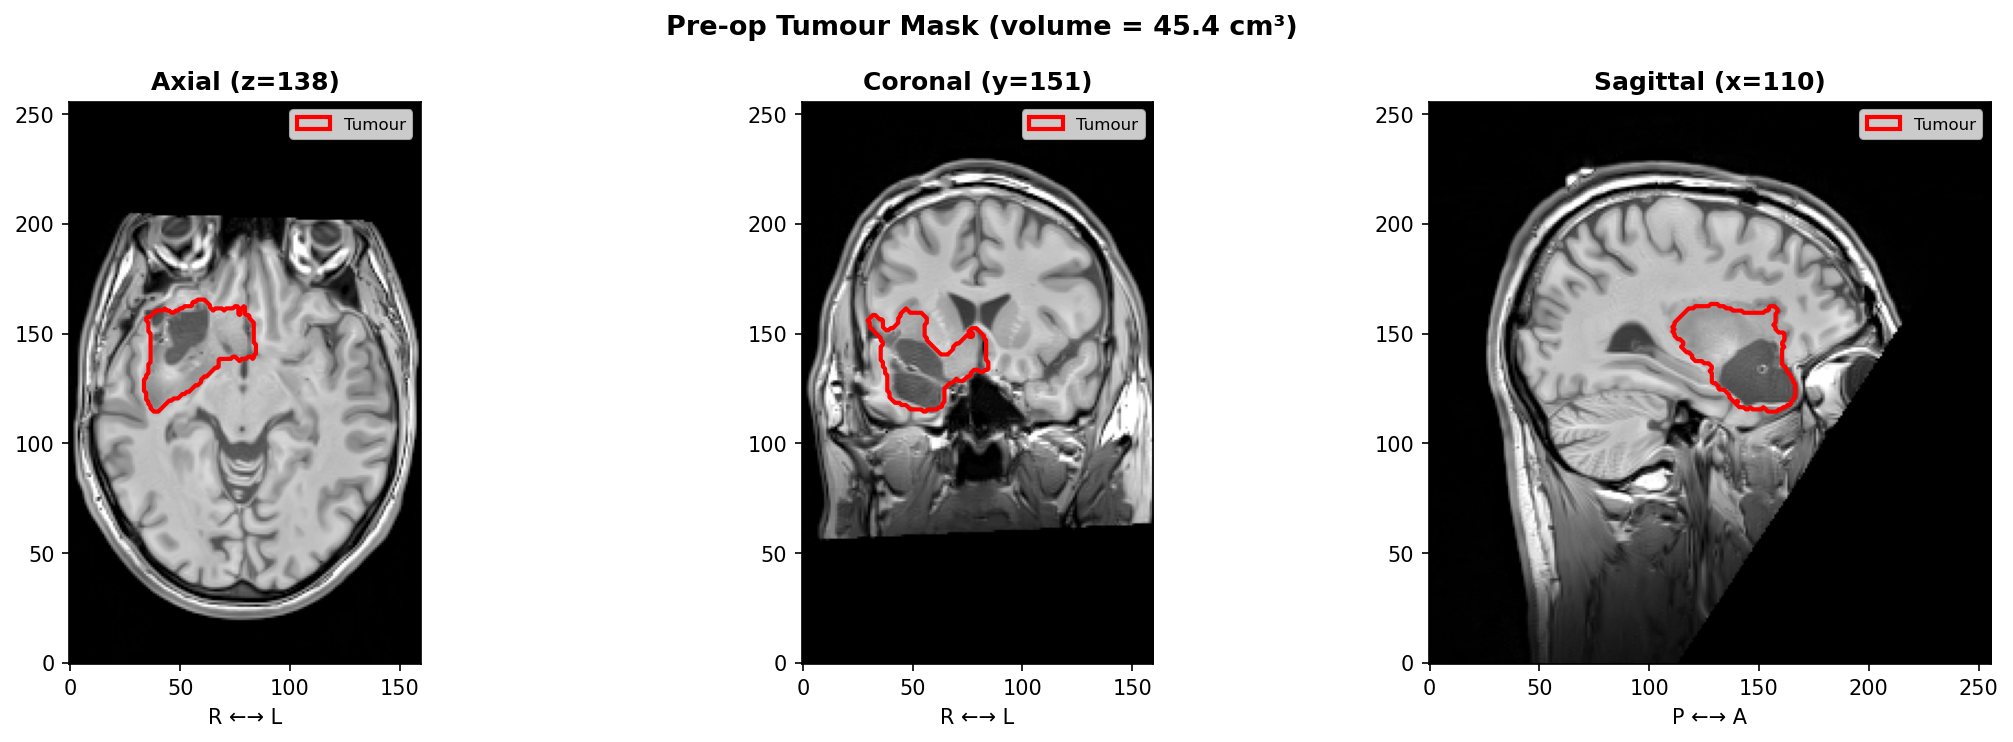

In [4]:
tumor_mask_path = BIDS_ROOT / 'derivatives' / 'tumor_masks' / 'sub-PAT16' / \
                  'anat' / 'sub-PAT16_space_T1_label-tumor_binary.nii.gz'

if tumor_mask_path.exists():
    tmask_img  = _to_ras(nib.load(str(tumor_mask_path)))
    tmask_data = np.asarray(tmask_img.dataobj)
    tumor_vol_cm3 = (tmask_data > 0).sum() * np.prod(tmask_img.header.get_zooms()[:3]) / 1000.0
    print(f'Tumour mask loaded: {(tmask_data > 0).sum()} voxels = {tumor_vol_cm3:.1f} cm\u00b3')

    # Find the slice with maximum tumour extent
    tumor_z_extent = (tmask_data > 0).sum(axis=(0, 1))
    best_z = np.argmax(tumor_z_extent)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'Pre-op Tumour Mask (volume = {tumor_vol_cm3:.1f} cm\u00b3)',
                 fontsize=13, fontweight='bold')

    # Radiological convention (RAS): patient R on viewer's left
    axes[0].imshow(t1_preop_data[::-1, :, best_z].T, origin='lower',
                   cmap='gray', vmax=vmax, aspect='equal')
    axes[0].contour(tmask_data[::-1, :, best_z].T, levels=[0.5],
                    colors='red', linewidths=2)
    axes[0].set_title(f'Axial (z={best_z})', fontweight='bold')
    axes[0].set_xlabel('R \u2190\u2192 L')

    tumor_y_extent = (tmask_data > 0).sum(axis=(0, 2))
    best_y = np.argmax(tumor_y_extent)
    axes[1].imshow(t1_preop_data[::-1, best_y, :].T, origin='lower',
                   cmap='gray', vmax=vmax, aspect='equal')
    axes[1].contour(tmask_data[::-1, best_y, :].T, levels=[0.5],
                    colors='red', linewidths=2)
    axes[1].set_title(f'Coronal (y={best_y})', fontweight='bold')
    axes[1].set_xlabel('R \u2190\u2192 L')

    tumor_x_extent = (tmask_data > 0).sum(axis=(1, 2))
    best_x = np.argmax(tumor_x_extent)
    axes[2].imshow(t1_preop_data[best_x, :, :].T, origin='lower',
                   cmap='gray', vmax=vmax, aspect='equal')
    axes[2].contour(tmask_data[best_x, :, :].T, levels=[0.5],
                    colors='red', linewidths=2)
    axes[2].set_title(f'Sagittal (x={best_x})', fontweight='bold')
    axes[2].set_xlabel('P \u2190\u2192 A')

    for ax in axes:
        ax.legend(handles=[mpatches.Patch(edgecolor='red', facecolor='none',
                  linewidth=2, label='Tumour')], fontsize=8)

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'figC03_03_tumor_overlay.png', bbox_inches='tight')
    plt.show()
else:
    print(f'Tumour mask not found at: {tumor_mask_path}')

---
## 5. FreeSurfer Parcellation (aparc+aseg)

FreeSurfer's `recon-all-clinical` pipeline segments the brain into
cortical and subcortical regions using the Desikan-Killiany atlas.
The `aparc+aseg` volume provides voxel-level labels for:

- 34 cortical parcels per hemisphere (68 total) -- used for connectivity
- Subcortical structures (thalamus, caudate, putamen, etc.)
- White matter, CSF, ventricles

This parcellation serves as the foundation for:
- **FE mesh generation** (NB\_C06): tissue classification $\to$ material properties
- **Structural connectivity** (NB\_C04): streamline endpoints $\to$ SC matrix
- **Functional connectivity** (NB\_C05): ROI time series $\to$ FC matrix
- **Displacement mapping** (NB\_C07): FEM displacement $\to$ per-parcel averages

aparc+aseg loaded: shape=(171, 266, 266), orientation=('R', 'A', 'S')
Unique labels: 104


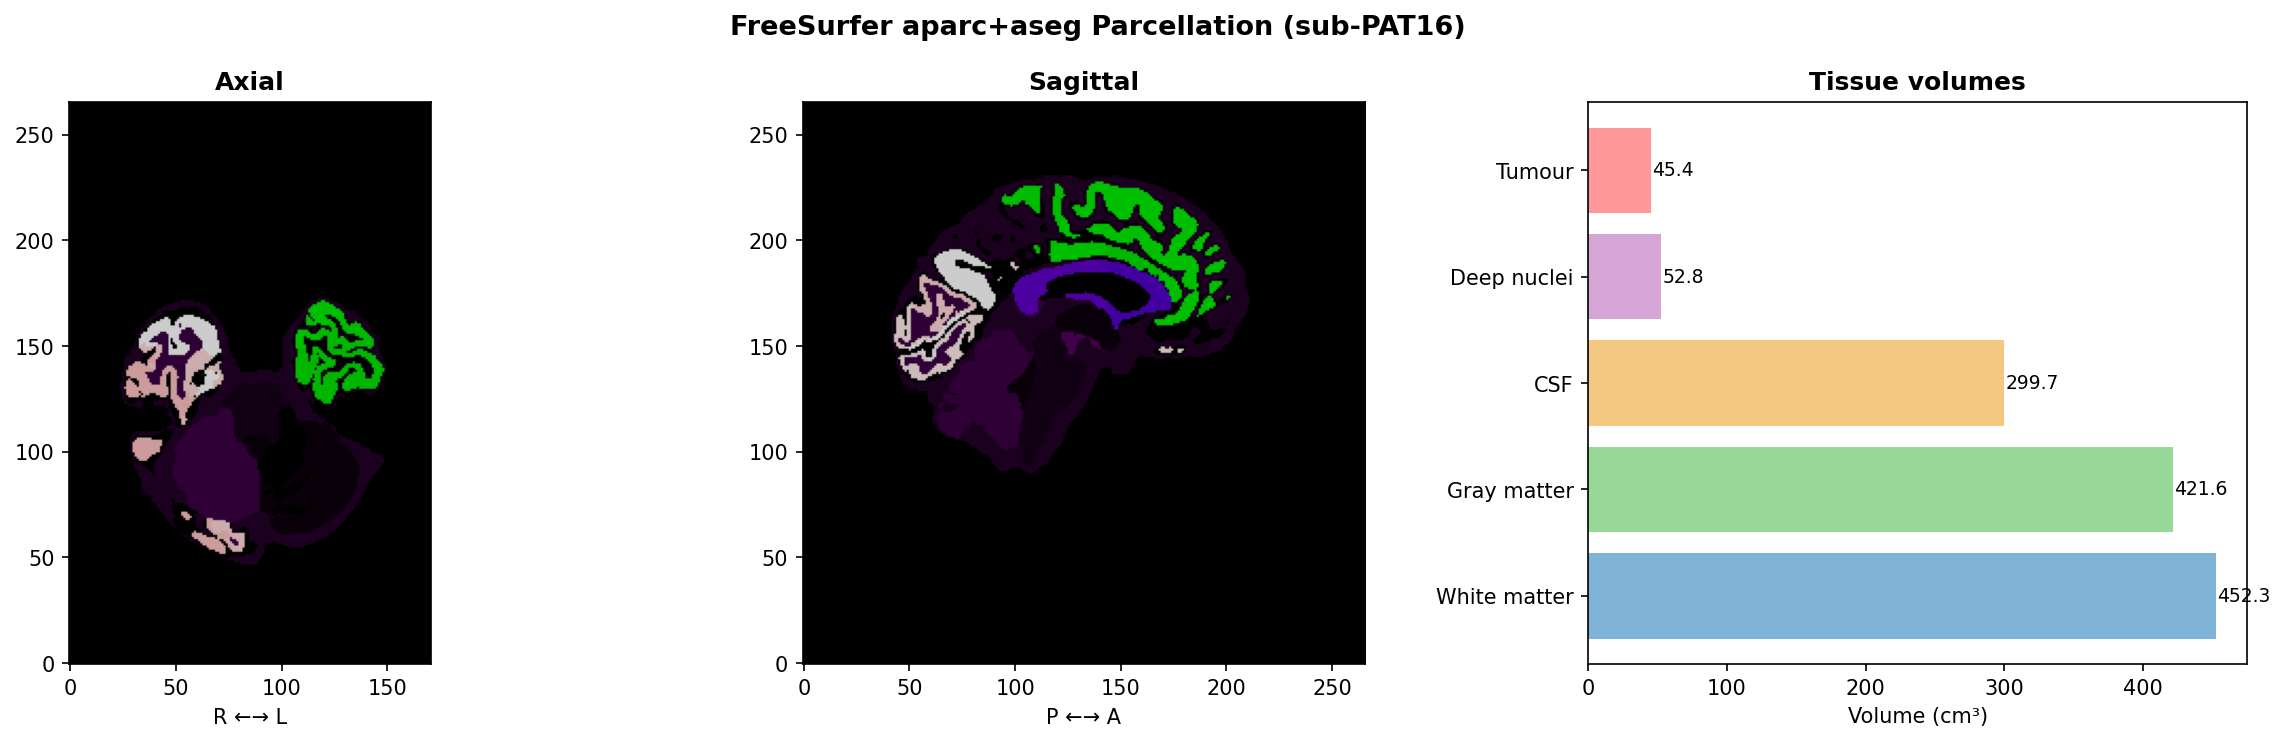


Tissue volume summary:
  White matter   :    452.3 cm³  (452,297 voxels)
  Gray matter    :    421.6 cm³  (421,585 voxels)
  CSF            :    299.7 cm³  (299,666 voxels)
  Deep nuclei    :     52.8 cm³  (52,838 voxels)
  Tumour         :     45.4 cm³  (45,431 voxels)


In [5]:
aseg_postop_path = REG_DIR / 'ses-postop' / 'aparc+aseg_space-T1w.nii.gz'
aseg_preop_path  = REG_DIR / 'ses-preop' / 'aparc+aseg_space-T1w.nii.gz'

aseg_path = aseg_postop_path if aseg_postop_path.exists() else aseg_preop_path
aseg_img  = nib.as_closest_canonical(nib.load(str(aseg_path)))
aseg_data = np.asarray(aseg_img.dataobj).astype(np.int32)
vox_vol   = np.prod(aseg_img.header.get_zooms()[:3])

print(f'aparc+aseg loaded: shape={aseg_data.shape}, '
      f'orientation={nib.aff2axcodes(aseg_img.affine)}')
print(f'Unique labels: {len(np.unique(aseg_data))}')

# Tissue classification
wm_labels  = {2, 41, 77, 251, 252, 253, 254, 255}
gm_labels  = set(range(1001, 1036)) | set(range(2001, 2036))
csf_labels = {4, 5, 14, 15, 24, 43, 44}
dn_labels  = {10, 11, 12, 13, 17, 18, 26, 28, 49, 50, 51, 52, 53, 54, 58, 60}

tissue_counts = {}
for name, labels in [('White matter', wm_labels), ('Gray matter', gm_labels),
                     ('CSF', csf_labels), ('Deep nuclei', dn_labels)]:
    mask = np.isin(aseg_data, list(labels))
    tissue_counts[name] = {'voxels': int(mask.sum()),
                           'volume_cm3': mask.sum() * vox_vol / 1000.0}

if tumor_mask_path.exists():
    tissue_counts['Tumour'] = {'voxels': int((tmask_data > 0).sum()),
                               'volume_cm3': tumor_vol_cm3}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('FreeSurfer aparc+aseg Parcellation (sub-PAT16)',
             fontsize=13, fontweight='bold')

# Radiological convention (RAS): patient R on viewer's left
mid_z = aseg_data.shape[2] // 2
axes[0].imshow(aseg_data[::-1, :, mid_z].T, origin='lower',
               cmap='nipy_spectral', aspect='equal')
axes[0].set_title('Axial', fontweight='bold')
axes[0].set_xlabel('R \u2190\u2192 L')

mid_sag = aseg_data.shape[0] // 2
axes[1].imshow(aseg_data[mid_sag, :, :].T, origin='lower',
               cmap='nipy_spectral', aspect='equal')
axes[1].set_title('Sagittal', fontweight='bold')
axes[1].set_xlabel('P \u2190\u2192 A')

# Tissue volumes
names = list(tissue_counts.keys())
vols  = [tissue_counts[n]['volume_cm3'] for n in names]
colors = ['#7FB3D8', '#98D898', '#F5C882', '#D5A6D5', '#FF9999']
bars = axes[2].barh(names, vols, color=colors[:len(names)])
axes[2].set_xlabel('Volume (cm\u00b3)')
axes[2].set_title('Tissue volumes', fontweight='bold')
for bar, vol in zip(bars, vols):
    axes[2].text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                 f'{vol:.1f}', va='center', fontsize=9)

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC03_04_parcellation.png', bbox_inches='tight')
plt.show()

print('\nTissue volume summary:')
for name, info in tissue_counts.items():
    print(f"  {name:15s}: {info['volume_cm3']:8.1f} cm\u00b3  ({info['voxels']:,} voxels)")

---
## 6. Pre-op vs Post-op Comparison

Side-by-side comparison at matched slices reveals the surgical changes:
the tumour region in the pre-op scan corresponds to a CSF-filled cavity
in the post-op scan, and the surrounding brain tissue has shifted.

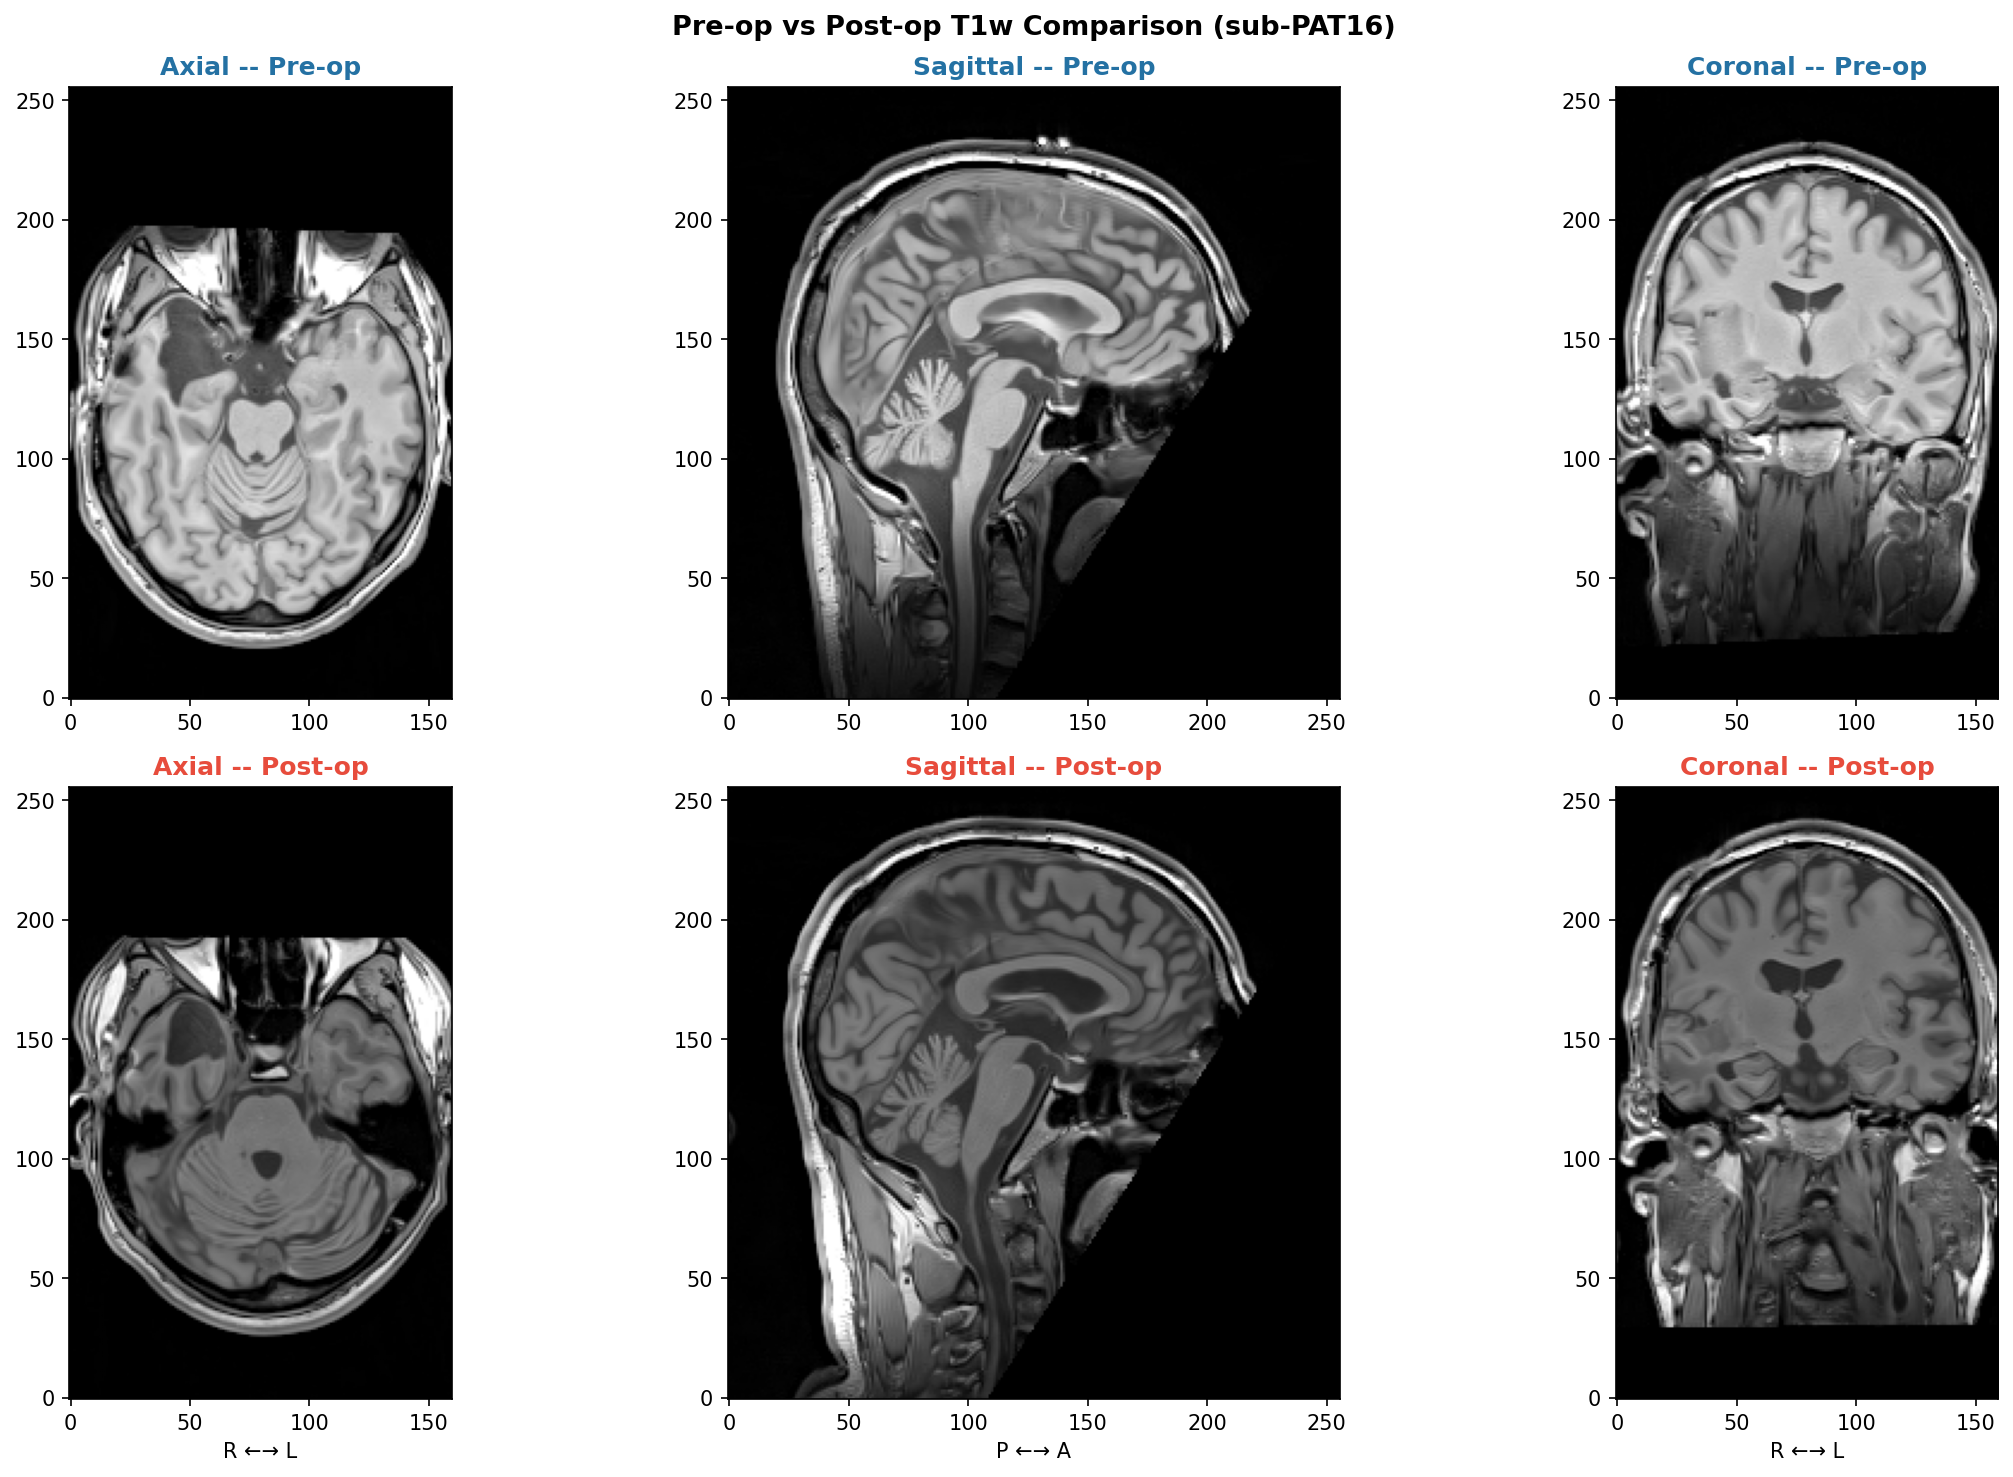

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Pre-op vs Post-op T1w Comparison (sub-PAT16)',
             fontsize=13, fontweight='bold')

s1 = t1_preop_data.shape
s2 = t1_postop_data.shape

# Radiological convention (RAS): patient R on viewer's left
for col, (plane, title) in enumerate([
    ('axial', 'Axial'), ('sagittal', 'Sagittal'), ('coronal', 'Coronal')
]):
    if plane == 'axial':
        pre_slice  = t1_preop_data[::-1, :, s1[2]//2].T
        post_slice = t1_postop_data[::-1, :, s2[2]//2].T
        xlabel = 'R \u2190\u2192 L'
    elif plane == 'sagittal':
        pre_slice  = t1_preop_data[s1[0]//2, :, :].T
        post_slice = t1_postop_data[s2[0]//2, :, :].T
        xlabel = 'P \u2190\u2192 A'
    else:
        pre_slice  = t1_preop_data[::-1, s1[1]//2, :].T
        post_slice = t1_postop_data[::-1, s2[1]//2, :].T
        xlabel = 'R \u2190\u2192 L'

    axes[0, col].imshow(pre_slice, origin='lower', cmap='gray',
                        vmax=vmax, aspect='equal')
    axes[0, col].set_title(f'{title} -- Pre-op', fontweight='bold',
                           color='#2471A3')

    axes[1, col].imshow(post_slice, origin='lower', cmap='gray',
                        vmax=vmax2, aspect='equal')
    axes[1, col].set_title(f'{title} -- Post-op', fontweight='bold',
                           color='#E74C3C')
    axes[1, col].set_xlabel(xlabel)

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC03_05_preop_vs_postop.png', bbox_inches='tight')
plt.show()

---
## 7. Interactive Visualisation with Freeview

> **Desktop only:** Freeview requires a local FreeSurfer installation with a display
> server. These commands will not work in Google Colab. On Colab you can still
> view the static figures generated above.

For interactive 3D exploration of the structural data, the following
Freeview commands can be run from the terminal. These load the T1w
images, segmentation overlays, and tumour/cavity masks.

### FreeSurfer surfaces and parcellation
```bash
bash scripts/freeview_freesurfer.sh --subject PAT16 --session preop
bash scripts/freeview_freesurfer.sh --subject PAT16 --session postop
```

### Pre-op vs post-op comparison
```bash
bash scripts/freeview_preop_postop.sh --subject PAT16
```

### Tumour vs cavity overlay
```bash
bash scripts/freeview_tumor_vs_cavity.sh --subject PAT16
```

### RESSEG cavity masks
```bash
bash scripts/freeview_resseg.sh --subject PAT16
```

**Tip:** Toggle layer visibility in the left sidebar panel. Use the
slice navigation panel at the bottom to scroll through slices.

---
## Summary

In this notebook we have:

- Loaded and visualised pre-op and post-op T1w images
- Identified the tumour (pre-op) and resection cavity (post-op)
- Explored the FreeSurfer aparc+aseg parcellation and tissue volumes
- Compared pre-op and post-op anatomy side by side
- Identified freeview scripts for interactive 3D exploration

The parcellation and tissue classification established here will be used
in subsequent notebooks:
- **NB\_C04**: aparc+aseg defines endpoints for structural connectivity
- **NB\_C05**: aparc+aseg defines ROIs for functional connectivity
- **NB\_C06**: tissue labels define material properties for the FE mesh
- **NB\_C07**: parcels are the nodes of the neural mass model

---

**Next:** [NB\_C04](NB_C04_Diffusion_MRI_Tractography.ipynb) -- Diffusion MRI, microstructure, and tractography